Connected to Python 3.13.2

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
class NN():
    def __init__(self, input_size , hidden_size , output_size,seed = None):
        self.input_size= input_size
        self.hidden_size= hidden_size
        self. output_size=  output_size

        if seed is not None:
            np.random.seed(seed)
        
        # initialize weights for input to hidden layer use sigmoid so xaviar initialization
        self.weights_input_hidden = np.random.randn(self.input_size , self.hidden_size)*np.sqrt(1.0/self.input_size)#用xavier
        #for hidden to output    
        self.weights_hidden_output = np.random.randn( self.hidden_size, self. output_size  )*np.sqrt(1.0/self.hidden_size)
        #initialize bias for hidden
        self.bias_hidden = np.zeros((1,self.hidden_size))
        #initialize bias for output
        self.bias_output = np.zeros((1,self. output_size))
        #record activ what we use
        self.output_activation_type = None
    def sigmoid(self , x):
        return 1/(1+np.exp(-x))   #sigmoid function
    def sigmoid_derivative(self , x):
        return x *(1-x)    #導數
    
    
    
    
    #define feedforward
    def feedforward(self, X,output_activation='sigmoid'):
        self.output_activation_type = output_activation
        #計算activation
        self.hidden_activation = np.dot(X,self.weights_input_hidden)+ self.bias_hidden
        #給activate function 給hidden
        self.hidden_output= self.sigmoid(self.hidden_activation)
        self.output_activation = np.dot(self.hidden_output, self.weights_hidden_output) + self.bias_output
        if output_activation == 'sigmoid':
           self.predicted_output = self.sigmoid(self.output_activation)   # classification
        elif output_activation == 'linear':
           self.predicted_output = self.output_activation                 # linear for forecast data
        else:
             raise ValueError("output_activation must be 'sigmoid' or 'linear'")
        return self.predicted_output




    #definr backward   #delta = (y-y^hat )*devira so +=
    def backward(self, X, y, learning_rate):
        #caculate the error at output
        output_error = y - self.predicted_output
        #caculate the delta at output
        output_delta = output_error *  self.sigmoid_derivative(self.predicted_output)
        #caculate the error and delta at hidden
        hidden_error = np.dot(output_delta, self.weights_hidden_output.T)
        hidden_delta = hidden_error * self.sigmoid_derivative(self.hidden_output)
        #update hidden w sigmoid_derivative so +=
        self.weights_hidden_output += np.dot(self.hidden_output.T,output_delta) * learning_rate
        self.bias_output += np.sum(output_delta, axis=0,keepdims=True) * learning_rate
        #update input w 
        self.weights_input_hidden += np.dot(X.T, hidden_delta) * learning_rate
        self.bias_hidden += np.sum(hidden_delta, axis=0,keepdims=True) * learning_rate

    def train(self,X,y,epochs,learning_rate,log = 2000,error_loss = 0.001,output_activation='sigmoid'):
        self.history_ = []
        for epoch in range(epochs):
            # get output
            output = self.feedforward(X , output_activation=output_activation )
            #update
            self.backward(X,y,learning_rate)
            loss = np.mean(np.square(y-output))   #MSE 
            self.history_.append(loss)   #record loss
            #set every epoch see
            if epoch % log == 0:
                print(f"Eppoch {epoch},Loss:{loss}")
            #same as earlystop    
            if (error_loss is not None) and (loss < error_loss):
                print(f"Early stopping at epoch {epoch}, Loss: {loss}")
                break
    def predict(self, X, task='classification',output_activation='sigmoid'):
        y_hat = self.feedforward(X, output_activation=output_activation)
        if task == 'classification':
            return (y_hat >= 0.5).astype(int) #true =1 false = 0
        return y_hat         

In [ ]:
import pandas as pd
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])


hidden_sizes = [2, 3, 4]           # different nodes
learning_rates = [0.5, 0.1, 0.05] # different learning
results = []
#doible loop for hidden and learning
for h in hidden_sizes:
    for lr in learning_rates:
        print(f"\n Training with hidden_size={h}, learning_rate={lr}")
        model = NN(input_size=2, hidden_size=h, output_size=1,seed= 42)
        model.train(X, y, epochs=10000, learning_rate=lr, error_loss=0.001, log=2000)
        final_loss = model.history_[-1] #record finallos
        
        epochs_trained = len(model.history_)
        
        # inspect every time
        y_pred = model.predict(X)
        y_prob = model.feedforward(X)
        accuracy = np.mean(y_pred == y) * 100
        results.append({
            "hidden_size": h,
            "learning_rate": lr,
            "final_loss": final_loss,
            "accuracy": accuracy
        })


 Training with hidden_size=2, learning_rate=0.5
Eppoch 0,Loss:0.2525704068634172
Eppoch 2000,Loss:0.12984524849314738
Eppoch 4000,Loss:0.12637719986665844
Eppoch 6000,Loss:0.125784459805956
Eppoch 8000,Loss:0.1255446167447618

 Training with hidden_size=2, learning_rate=0.1
Eppoch 0,Loss:0.2525704068634172
Eppoch 2000,Loss:0.24977188607369302
Eppoch 4000,Loss:0.2453212409390333
Eppoch 6000,Loss:0.15506605777462779
Eppoch 8000,Loss:0.1338667285520156

 Training with hidden_size=2, learning_rate=0.05
Eppoch 0,Loss:0.2525704068634172
Eppoch 2000,Loss:0.24993787692001468
Eppoch 4000,Loss:0.24977179814752465
Eppoch 6000,Loss:0.24920905905073715
Eppoch 8000,Loss:0.24531238523110152

 Training with hidden_size=3, learning_rate=0.5
Eppoch 0,Loss:0.27457539322283253
Eppoch 2000,Loss:0.0025361702156669235
Early stopping at epoch 3669, Loss: 0.000999769172394217

 Training with hidden_size=3, learning_rate=0.1
Eppoch 0,Loss:0.27457539322283253
Eppoch 2000,Loss:0.18935267137341363
Eppoch 4000,Los

In [ ]:
df = pd.DataFrame(results)
print("\n hypreparameter test result：")
print(df)

y_pred = model.predict(X)
print("output prediction：", y_pred)
print(f"Final loss: {model.history_[-1]}")


 hypreparameter test result：
   hidden_size  learning_rate  final_loss  accuracy
0            2           0.50    0.125416      50.0
1            2           0.10    0.129840      50.0
2            2           0.05    0.207334      75.0
3            3           0.50    0.001000     100.0
4            3           0.10    0.002536     100.0
5            3           0.05    0.012768     100.0
6            4           0.50    0.001000     100.0
7            4           0.10    0.003143     100.0
8            4           0.05    0.042674     100.0
output prediction： [[0]
 [1]
 [1]
 [0]]
Final loss: 0.04267441073813763



 Statistics

 Final Loss:
   Mean: 0.058412
   Std:  0.076542
   Min:  0.001000
   Max:  0.207334


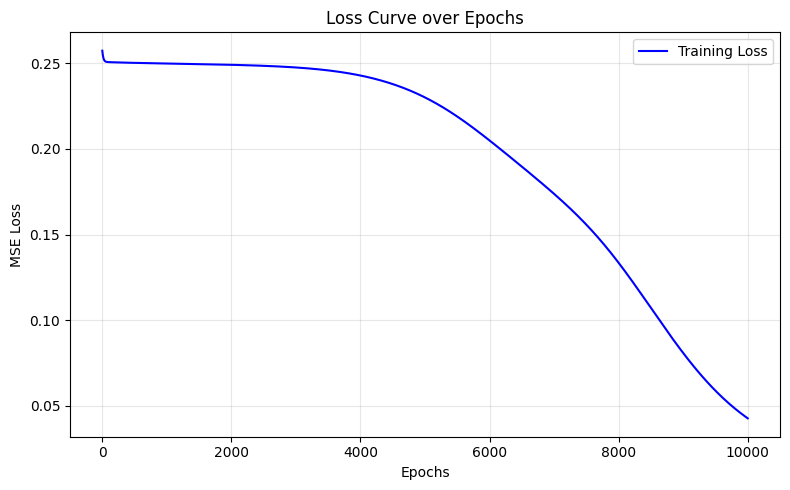

In [ ]:
print("\n" + "=" * 70)
print(" Statistics")
print("=" * 70)


print(f"\n Final Loss:")
print(f"   Mean: {df['final_loss'].mean():.6f}")
print(f"   Std:  {df['final_loss'].std():.6f}")
print(f"   Min:  {df['final_loss'].min():.6f}")
print(f"   Max:  {df['final_loss'].max():.6f}")
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(model.history_, label="Training Loss", color='blue')
plt.title("Loss Curve over Epochs")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


























# iris binary input =2